In [2]:
# Business Problem

# Aircraft company currently facing challenges due to several factors affecting their operations.
# company wants to analyze their database to find ways to increase their occupancy rate,
# which can help boost the average profit earned per seat.

In [3]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# Connecting Sqlite database to python using sqlite3 library.

connection=sqlite3.connect('travel.sqlite')
cursor=connection.cursor()

In [5]:
# It is important to understand the structure of the data and to identify which tables are relevant for analysis.
# This can help in formulating queries to extract the necessary information for analysis.

cursor.execute('''select name from sqlite_master where type='table';''')
print('list of table present in database')
results=cursor.fetchall()
table_list=[]
for table in results:
  table_name=table[0]
  table_list.append(table_name)
table_list

list of table present in database


['aircrafts_data',
 'airports_data',
 'boarding_passes',
 'bookings',
 'flights',
 'seats',
 'ticket_flights',
 'tickets']

In [6]:
aircrafts_data=pd.read_sql_query('select * from aircrafts_data',connection)
aircrafts_data

,aircraft_code,model,range
0,773,"{""en"": ""Boeing 777-300"", ""ru"": ""Боинг 777-300""}",11100
1,763,"{""en"": ""Boeing 767-300"", ""ru"": ""Боинг 767-300""}",7900
2,SU9,"{""en"": ""Sukhoi Superjet-100"", ""ru"": ""Сухой Суп...",3000
3,320,"{""en"": ""Airbus A320-200"", ""ru"": ""Аэробус A320-...",5700
4,321,"{""en"": ""Airbus A321-200"", ""ru"": ""Аэробус A321-...",5600
5,319,"{""en"": ""Airbus A319-100"", ""ru"": ""Аэробус A319-...",6700
6,733,"{""en"": ""Boeing 737-300"", ""ru"": ""Боинг 737-300""}",4200
7,CN1,"{""en"": ""Cessna 208 Caravan"", ""ru"": ""Сессна 208...",1200
8,CR2,"{""en"": ""Bombardier CRJ-200"", ""ru"": ""Бомбардье ...",2700


In [7]:
airports_data=pd.read_sql_query('select * from airports_data',connection)
airports_data

,airport_code,airport_name,city,coordinates,timezone
0,YKS,"{""en"": ""Yakutsk Airport"", ""ru"": ""Якутск""}","{""en"": ""Yakutsk"", ""ru"": ""Якутск""}","(129.77099609375,62.0932998657226562)",Asia/Yakutsk
1,MJZ,"{""en"": ""Mirny Airport"", ""ru"": ""Мирный""}","{""en"": ""Mirnyj"", ""ru"": ""Мирный""}","(114.03900146484375,62.534698486328125)",Asia/Yakutsk
2,KHV,"{""en"": ""Khabarovsk-Novy Airport"", ""ru"": ""Хабар...","{""en"": ""Khabarovsk"", ""ru"": ""Хабаровск""}","(135.18800354004,48.5279998779300001)",Asia/Vladivostok
3,PKC,"{""en"": ""Yelizovo Airport"", ""ru"": ""Елизово""}","{""en"": ""Petropavlovsk"", ""ru"": ""Петропавловск-К...","(158.453994750976562,53.1679000854492188)",Asia/Kamchatka
4,UUS,"{""en"": ""Yuzhno-Sakhalinsk Airport"", ""ru"": ""Хом...","{""en"": ""Yuzhno-Sakhalinsk"", ""ru"": ""Южно-Сахали...","(142.718002319335938,46.8886985778808594)",Asia/Sakhalin
...,...,...,...,...,...
99,MMK,"{""en"": ""Murmansk Airport"", ""ru"": ""Мурманск""}","{""en"": ""Murmansk"", ""ru"": ""Мурманск""}","(32.7508010864257812,68.7817001342773438)",Europe/Moscow
100,ABA,"{""en"": ""Abakan Airport"", ""ru"": ""Абакан""}","{""en"": ""Abakan"", ""ru"": ""Абакан""}","(91.3850021362304688,53.7400016784667969)",Asia/Krasnoyarsk
101,BAX,"{""en"": ""Barnaul Airport"", ""ru"": ""Барнаул""}","{""en"": ""Barnaul"", ""ru"": ""Барнаул""}","(83.5384979248046875,53.363800048828125)",Asia/Krasnoyarsk
102,AAQ,"{""en"": ""Anapa Vityazevo Airport"", ""ru"": ""Витяз...","{""en"": ""Anapa"", ""ru"": ""Анапа""}","(37.3473014831539984,45.002101898192997)",Europe/Moscow


In [8]:
boarding_passes=pd.read_sql_query('select * from boarding_passes',connection)
boarding_passes

,ticket_no,flight_id,boarding_no,seat_no
0,0005435212351,30625,1,2D
1,0005435212386,30625,2,3G
2,0005435212381,30625,3,4H
3,0005432211370,30625,4,5D
4,0005435212357,30625,5,11A
...,...,...,...,...
579681,0005434302871,19945,85,20F
579682,0005432892791,19945,86,21C
579683,0005434302869,19945,87,20E
579684,0005432802476,19945,88,21F


In [9]:
bookings=pd.read_sql_query('select * from bookings',connection)
bookings

,book_ref,book_date,total_amount
0,00000F,2017-07-05 03:12:00+03,265700
1,000012,2017-07-14 09:02:00+03,37900
2,000068,2017-08-15 14:27:00+03,18100
3,000181,2017-08-10 13:28:00+03,131800
4,0002D8,2017-08-07 21:40:00+03,23600
...,...,...,...
262783,FFFEF3,2017-07-17 07:23:00+03,56000
262784,FFFF2C,2017-08-08 05:55:00+03,10800
262785,FFFF43,2017-07-20 20:42:00+03,78500
262786,FFFFA8,2017-08-08 04:45:00+03,28800


In [10]:
flights=pd.read_sql_query('select * from flights',connection)
flights

,flight_id,flight_no,scheduled_departure,scheduled_arrival,departure_airport,arrival_airport,status,aircraft_code,actual_departure,actual_arrival
0,1185,PG0134,2017-09-10 09:50:00+03,2017-09-10 14:55:00+03,DME,BTK,Scheduled,319,\N,\N
1,3979,PG0052,2017-08-25 14:50:00+03,2017-08-25 17:35:00+03,VKO,HMA,Scheduled,CR2,\N,\N
2,4739,PG0561,2017-09-05 12:30:00+03,2017-09-05 14:15:00+03,VKO,AER,Scheduled,763,\N,\N
3,5502,PG0529,2017-09-12 09:50:00+03,2017-09-12 11:20:00+03,SVO,UFA,Scheduled,763,\N,\N
4,6938,PG0461,2017-09-04 12:25:00+03,2017-09-04 13:20:00+03,SVO,ULV,Scheduled,SU9,\N,\N
...,...,...,...,...,...,...,...,...,...,...
33116,33117,PG0063,2017-08-02 19:25:00+03,2017-08-02 20:10:00+03,SKX,SVO,Arrived,CR2,2017-08-02 19:25:00+03,2017-08-02 20:10:00+03
33117,33118,PG0063,2017-07-28 19:25:00+03,2017-07-28 20:10:00+03,SKX,SVO,Arrived,CR2,2017-07-28 19:30:00+03,2017-07-28 20:15:00+03
33118,33119,PG0063,2017-09-08 19:25:00+03,2017-09-08 20:10:00+03,SKX,SVO,Scheduled,CR2,\N,\N
33119,33120,PG0063,2017-08-01 19:25:00+03,2017-08-01 20:10:00+03,SKX,SVO,Arrived,CR2,2017-08-01 19:26:00+03,2017-08-01 20:12:00+03


In [11]:
seats=pd.read_sql_query('select * from seats',connection)
seats

,aircraft_code,seat_no,fare_conditions
0,319,2A,Business
1,319,2C,Business
2,319,2D,Business
3,319,2F,Business
4,319,3A,Business
...,...,...,...
1334,773,48H,Economy
1335,773,48K,Economy
1336,773,49A,Economy
1337,773,49C,Economy


In [12]:
ticket_flights=pd.read_sql_query('select * from ticket_flights',connection)
ticket_flights

,ticket_no,flight_id,fare_conditions,amount
0,0005432159776,30625,Business,42100
1,0005435212351,30625,Business,42100
2,0005435212386,30625,Business,42100
3,0005435212381,30625,Business,42100
4,0005432211370,30625,Business,42100
...,...,...,...,...
1045721,0005435097522,32094,Economy,5200
1045722,0005435097521,32094,Economy,5200
1045723,0005435104384,32094,Economy,5200
1045724,0005435104352,32094,Economy,5200


In [13]:
tickets=pd.read_sql_query('select * from tickets',connection)
tickets

,ticket_no,book_ref,passenger_id
0,0005432000987,06B046,8149 604011
1,0005432000988,06B046,8499 420203
2,0005432000989,E170C3,1011 752484
3,0005432000990,E170C3,4849 400049
4,0005432000991,F313DD,6615 976589
...,...,...,...
366728,0005435999869,D730BA,0474 690760
366729,0005435999870,D730BA,6535 751108
366730,0005435999871,A1AD46,1596 156448
366731,0005435999872,7B6A53,9374 822707


In [14]:
# knowing the data types of each column in the tables.

for table in table_list:
    data=pd.read_sql_query(f'select * from {table} limit 1',connection)
    print(table)
    print(data.dtypes)
    print()

aircrafts_data
aircraft_code      str
model              str
range            int64
dtype: object

airports_data
airport_code    str
airport_name    str
city            str
coordinates     str
timezone        str
dtype: object

boarding_passes
ticket_no        str
flight_id      int64
boarding_no    int64
seat_no          str
dtype: object

bookings
book_ref          str
book_date         str
total_amount    int64
dtype: object

flights
flight_id              int64
flight_no                str
scheduled_departure      str
scheduled_arrival        str
departure_airport        str
arrival_airport          str
status                   str
aircraft_code            str
actual_departure         str
actual_arrival           str
dtype: object

seats
aircraft_code      str
seat_no            str
fare_conditions    str
dtype: object

ticket_flights
ticket_no            str
flight_id          int64
fare_conditions      str
amount             int64
dtype: object

tickets
ticket_no       str
book_r

In [15]:
# knowing the number of missing values in each column of the tables.

for table in table_list:
    print('\ntable :',table)
    df_table=pd.read_sql_query(f'select * from {table}',connection)
    print(df_table.isnull().sum())


table : aircrafts_data
aircraft_code    0
model            0
range            0
dtype: int64

table : airports_data
airport_code    0
airport_name    0
city            0
coordinates     0
timezone        0
dtype: int64

table : boarding_passes
ticket_no      0
flight_id      0
boarding_no    0
seat_no        0
dtype: int64

table : bookings
book_ref        0
book_date       0
total_amount    0
dtype: int64

table : flights
flight_id              0
flight_no              0
scheduled_departure    0
scheduled_arrival      0
departure_airport      0
arrival_airport        0
status                 0
aircraft_code          0
actual_departure       0
actual_arrival         0
dtype: int64

table : seats
aircraft_code      0
seat_no            0
fare_conditions    0
dtype: int64

table : ticket_flights
ticket_no          0
flight_id          0
fare_conditions    0
amount             0
dtype: int64

table : tickets
ticket_no       0
book_ref        0
passenger_id    0
dtype: int64


In [16]:
# To answer our business problem, we need to find the aircrafts which have more than 100 seats.
# This will help us identify the aircrafts that have a higher capacity and can potentially increase
# the occupancy rate and profit per seat.

pd.read_sql_query('''select aircraft_code,count(seat_no) as seat_count from seats
 group by aircraft_code having seat_count>100 order by seat_count DESC''',connection)

,aircraft_code,seat_count
0,773,402
1,763,222
2,321,170
3,320,140
4,733,130
5,319,116


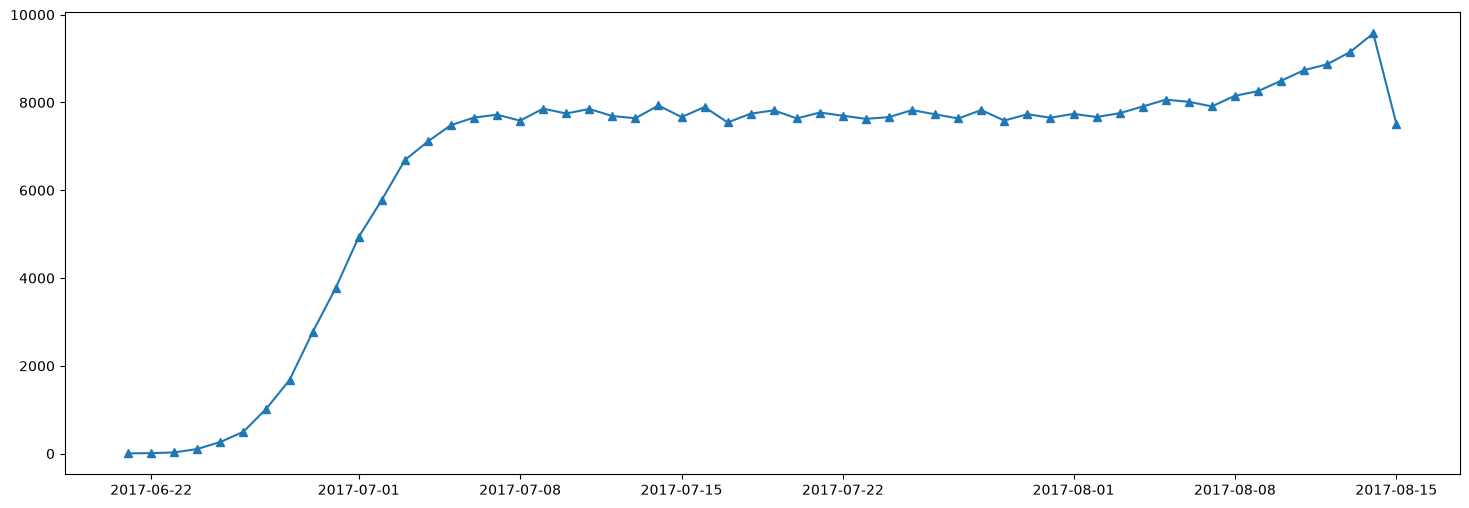

In [17]:
# To answer our business problem, we need to analyze the number of tickets booked on each date. 
# This will help us understand the booking trends and identify any patterns or fluctuations in ticket sales over time.

tickets=pd.read_sql_query("""select * from tickets join bookings
                   on tickets.book_ref=bookings.book_ref""",connection)
tickets['book_date']=pd.to_datetime(tickets['book_date'])
tickets['date']=tickets['book_date'].dt.date
x=tickets.groupby('date')['date'].count()
plt.figure(figsize=(18,6))
plt.plot(x.index,x.values,marker='^')
plt.show()

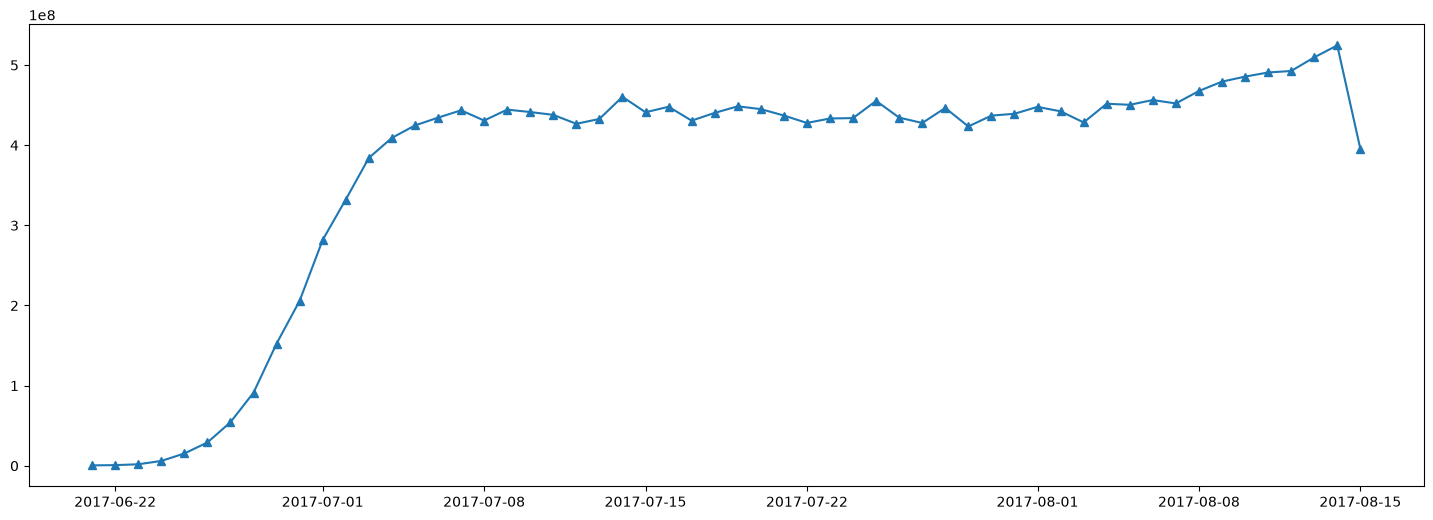

In [18]:
# To answer our business problem, we need to analyze the total amount of bookings made on each date.
# This will help us understand the revenue generated from ticket sales and identify any trends or
# fluctuations in booking amounts over time.

bookings=pd.read_sql_query('select * from bookings',connection)
bookings['book_date']=pd.to_datetime(bookings['book_date'])
bookings['book_date']=bookings['book_date'].dt.date
x=bookings.groupby('book_date')['total_amount'].sum()
plt.figure(figsize=(18,6))
plt.plot(x.index,x.values,marker='^')
plt.show()

<Axes: xlabel='aircraft_code', ylabel='amount'>

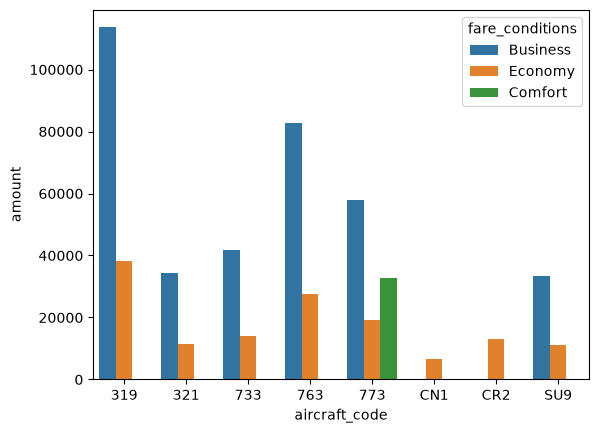

In [19]:
# Analyze the average amount of bookings made for each fare condition and aircraft code.

df=pd.read_sql_query('select fare_conditions,aircraft_code,avg(amount) as amount from ticket_flights join flights on ticket_flights.flight_id=flights.flight_id group by aircraft_code,fare_conditions',connection)
sns.barplot(data=df,x='aircraft_code',y='amount',hue='fare_conditions')

In [20]:
# calculating the total revenue per year and the average revenue per ticket

pd.read_sql_query('''select aircraft_code,total_tickets,total_revenue, total_revenue/total_tickets as average_revenue_per_ticket from
(select flights.aircraft_code,count(ticket_flights.flight_id) as total_tickets,sum(ticket_flights.amount) as total_revenue from flights 
join ticket_flights on flights.flight_id=ticket_flights.flight_id group by flights.aircraft_code order by total_revenue desc)''',connection)

,aircraft_code,total_tickets,total_revenue,average_revenue_per_ticket
0,SU9,365698,5114484700,13985
1,763,124774,4371277100,35033
2,773,144376,3431205500,23765
3,319,52853,2706163100,51201
4,CR2,150122,1982760500,13207
5,321,107129,1638164100,15291
6,733,86102,1426552100,16568
7,CN1,14672,96373800,6568


In [21]:
# Analyzing average Occupancy Rate for each aircraft

occupancy_rate=pd.read_sql_query('''select a.aircraft_code,avg(a.total_passengers) as booked_seats, b.num_seats,avg(a.total_passengers)/b.num_seats as occupancy_rate
from
(select aircraft_code, flights.flight_id, count(*) as total_passengers from boarding_passes join flights on boarding_passes.flight_id=flights.flight_id group by aircraft_code,flights.flight_id) as a
join (select aircraft_code,count(*) as num_seats from seats group by aircraft_code) as b
on a.aircraft_code=b.aircraft_code group by a.aircraft_code''',connection)

occupancy_rate.sort_values(by='occupancy_rate',ascending=False,inplace=True)
occupancy_rate



,aircraft_code,booked_seats,num_seats,occupancy_rate
4,773,264.925806,402,0.659019
2,733,80.255462,130,0.617350
7,SU9,56.812113,97,0.585692
1,321,88.809231,170,0.522407
3,763,113.937294,222,0.513231
5,CN1,6.004431,12,0.500369
0,319,53.583181,116,0.461924
6,CR2,21.482847,50,0.429657


In [22]:
# calculating how much the total annual turnover could increase by giving all the aircrafts a 10% increase in occupancy rate. 


occupancy_rate['increased_occupancy_rate'] = occupancy_rate['occupancy_rate']+occupancy_rate['occupancy_rate'] * 0.1
total_revenue=pd.read_sql_query('''select aircraft_code,sum(amount) as total_revenue from ticket_flights join flights 
                     on ticket_flights.flight_id=flights.flight_id group by aircraft_code''',connection)
occupancy_rate['Total_annual_turnover_increase']=total_revenue['total_revenue']/occupancy_rate['occupancy_rate']*occupancy_rate['increased_occupancy_rate']
occupancy_rate

,aircraft_code,booked_seats,num_seats,occupancy_rate,increased_occupancy_rate,Total_annual_turnover_increase
4,773,264.925806,402,0.659019,0.724921,3.774326e+09
2,733,80.255462,130,0.617350,0.679085,1.569207e+09
7,SU9,56.812113,97,0.585692,0.644261,5.625933e+09
1,321,88.809231,170,0.522407,0.574648,1.801981e+09
3,763,113.937294,222,0.513231,0.564554,4.808405e+09
5,CN1,6.004431,12,0.500369,0.550406,1.060112e+08
0,319,53.583181,116,0.461924,0.508116,2.976779e+09
6,CR2,21.482847,50,0.429657,0.472623,2.181037e+09


In [1]:
# The analysis shows significant differences in revenue generation, ticket value, and seat utilization across aircraft types.

# - Aircraft 319 generates an average revenue per ticket of ₹51,201, the highest among the aircraft analyzed. It also records the highest average booking amount in both Business and Economy classes, indicating strong revenue generation per passenger.
# - Aircraft SU9 generates the highest total revenue of ₹5.11 billion, but its average revenue per ticket is only ₹13,985, suggesting that its high total revenue is primarily driven by higher booking volume rather than higher ticket value.
# - Aircraft 773 has the highest occupancy rate at 65% with 402 seats, indicating strong utilization of its available seating capacity.
# - Aircraft CN1 has the lowest total revenue of ₹96.37 million and the lowest average revenue per ticket of ₹6,568. It has only 12 seats and an occupancy rate of 50%, limiting its overall revenue contribution.

# Overall, the analysis indicates that different aircraft contribute to business performance in different ways: 319 stands out for high-value bookings, SU9 for overall revenue volume, and 773 for seat utilization. CN1 has relatively limited revenue contribution due to its small seating capacity and lower ticket value.